In [10]:
from backend.utils.gmsh_function import *
from backend.utils.file_path import *
from backend.src.radiation_algorithm.radiation_algorithm import *

from plate_gmsh import *

from backend.cma.cma_algorithm import cma_algorithm
from backend.cma.cma_frequency_sweep import cma_frequency_sweep
from backend.cma.modal_current import ModalCurrent
from backend.cma.modal_farfield import compute_modal_farfield
from backend.cma.modal_visualizer import ModalVisualizer
from backend.cma.modal_significance import modal_significance

In [11]:
name = "plate"
path = setup_save_file_paths(name)

In [12]:
cm = 1e-2 # 1 cm
mm = 1e-3 # 1 mm

Long = 80 * mm
larg = 90 * mm

print("plate size: long =", Long, "width =", larg)

initial_mesh_size = 7 * mm

plate size: long = 0.08 width = 0.09


In [13]:
# Coding the Nice CubeSat geometry
gmsh.initialize()

gmsh.model.add("CubeSat")

setup_performance_config()

plate = construct_plate_geometry(Long, larg)

generate_and_save_mesh(path, initial_mesh_size)

# gmsh.fltk.run()

gmsh.finalize()

[PERFORMANCE] Gmsh configured to utilize 16 threads.
Geometry file saved in data/gmsh_files/plate.brep successfully
--- Starting Mesh Optimization (Dim: 2) ---
--- Optimization Complete ---
Mesh file saved in data/gmsh_files/plate.msh successfully


In [14]:
feed_point = np.array([Long/2, larg/2, 0])  # Feed point coordinates (x, y, z)

light_speed = 3e8
frequency = 1e9

wavelength = light_speed / frequency
print(f"wavelength = {wavelength} Meter")

wavelength = 0.3 Meter


_ = radiation_algorithm(path, frequency, feed_point, 
                        excitation_unit_vector='x',
                        gap_width=2*initial_mesh_size,
                        show=True, save_image=False)

## Characteristic Mode Analysis (CMA)

Both `cma_frequency_sweep()` and `cma_algorithm()` are self-sufficient: they re-derive the
mesh from `path.msh` and (re)compute the impedance matrix themselves, rather than trusting
whatever `path.mat_mesh2`/`path.mat_impedance` last happened to contain. The
`radiation_algorithm()` call above only needs to have run once so `frequency` is defined.

Each of them also writes a Markdown data sheet into `data/antennas_cma/`
(`plate_cma_report.md` and `plate_cma_sweep_report.md`) recording the mesh, the electrical
size, the solver settings, every mode's `lambda` / `MS` / `delta`, and the numerical state
of the impedance matrix — so a run can still be read once this session is gone. Pass
`write_report=False` to skip it.

1. Eigenvalues lambda_n(f) over a frequency range (`cma_frequency_sweep`), plotted for the
   first 4 modes.
2. Modal Significance MS_n(f) = 1/sqrt(1 + lambda_n^2) for the same 4 modes.
3. Characteristic currents and far-field patterns of the first 4 modes, at the plate's
   design frequency (`frequency` = 1 GHz).

In [15]:
# 1. Eigenvalues over a frequency range
n_modes_cma = 4

freq_start_cma = 0.3e9
freq_stop_cma = 2.0e9

sweep_data = cma_frequency_sweep(path, freq_start_cma, freq_stop_cma, n_points=11, n_modes=n_modes_cma)

Mesh ready: 216 points, 380 triangles, 545 edges -- regenerated from data/gmsh_files/plate.msh

Assembling Z(f) for 11 frequencies (545x545 edges) on GPU (NVIDIA T600 Laptop GPU, CuPy 14.1.1) -- geometry reused across the whole sweep...
[calculate_z_matrice_sweep] Using GPU (NVIDIA T600 Laptop GPU, CuPy 14.1.1) for the impedance matrix assembly (545x545 edges, 11 frequencies).
Z(f) assembly done in 43.2 s (3.931 s/frequency amortised)

Step 1/11 |   300.00 MHz | lambda: -108.287, -130.691, 295.076, -22790.230
Step 2/11 |   470.00 MHz | lambda: -26.396, -32.458, 80.310, -2396.388
Step 3/11 |   640.00 MHz | lambda: -9.597, -12.185, 33.889, -504.829
Step 4/11 |   810.00 MHz | lambda: -4.080, -5.504, 17.895, -151.953
Step 5/11 |   980.00 MHz | lambda: -1.961, -2.831, 10.908, -56.590
Step 6/11 |  1150.00 MHz | lambda: -0.927, -1.552, 7.328, -24.087
Step 7/11 |  1320.00 MHz | lambda: -0.434, -0.883, 5.275, -11.145
Step 8/11 |  1490.00 MHz | lambda: -0.157, -0.493, 3.995, -5.395
Step 9/11 |  

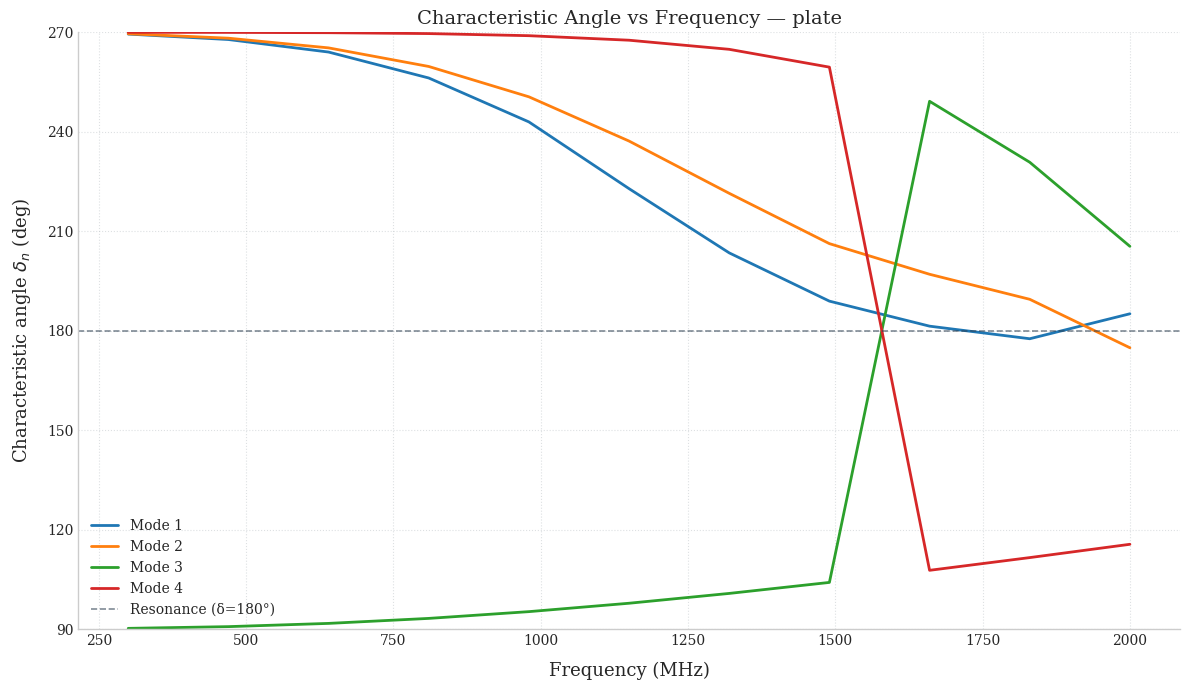

In [16]:
# 2. Characteristic angle delta_n = 180 - atan(lambda_n)
ModalVisualizer.plot_characteristic_angle_vs_frequency(sweep_data, n_modes_to_plot=n_modes_cma, antenna_name=path.name)

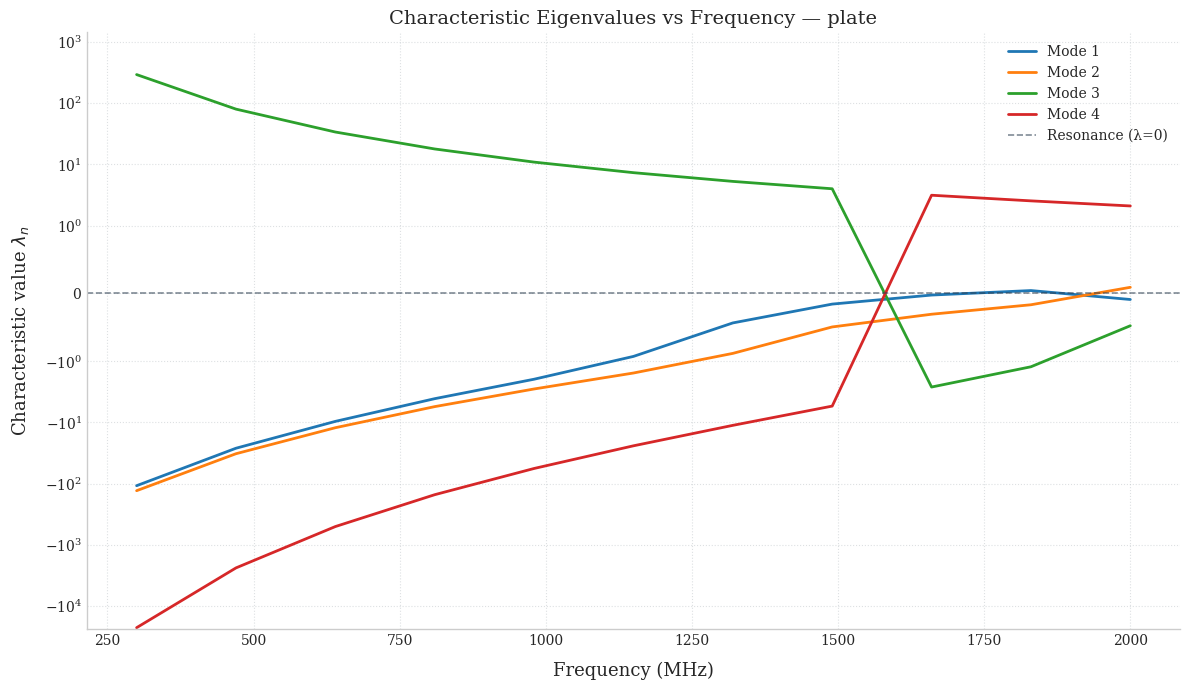

In [17]:
# 3. Eigenvalue curve for the first 4 modes
ModalVisualizer.plot_eigenvalues_vs_frequency(sweep_data, n_modes_to_plot=n_modes_cma, antenna_name=path.name)

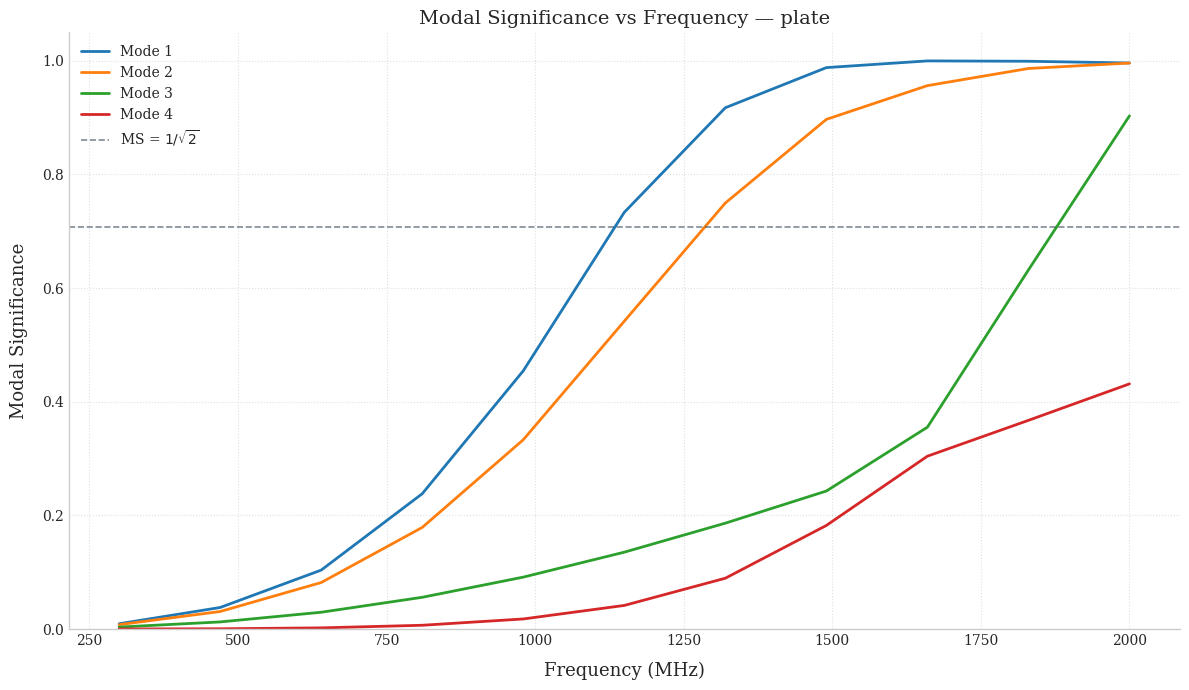

In [18]:
# 3. Modal Significance for the first 4 modes
ModalVisualizer.plot_modal_significance(sweep_data, n_modes_to_plot=n_modes_cma, antenna_name=path.name)

In [ ]:
# 4. Characteristic currents of the first 4 modes, at the plate's design frequency
n_modes_cma = 4
modal_data = cma_algorithm(path, frequency=frequency, n_modes=n_modes_cma,
                           show=True, save_image=False, show_current_arrows=True)

[calculate_z_matrice] GPU skipped: needs room for a 0.00 GB Z matrix (plus working space) but the device reports 0.00 GB free -- another application is probably using it. Falling back to CPU, which is correct but will be noticeably slower for this mesh. Free the GPU and re-run to use it.


In [ ]:
# 5. Far-field pattern of the first 4 modes, at the same design frequency
_, triangles, edges, _vecteurs_rho = DataManager_rwg2.load_data(path.mat_mesh2)
freq_cma, _omega, _mu, _epsilon, light_speed_c, eta, _Z = DataManager_rwg3.load_data(path.mat_impedance)

for n in range(n_modes_cma):
    J_n = modal_data.eigenvectors[:, n]
    sphere_points, sphere_triangles, gain_db, directivity_max = compute_modal_farfield(
        triangles, edges, J_n, freq_cma, light_speed_c, eta)
    print(f"Mode {n + 1} (lambda = {modal_data.eigenvalues[n]:.4f}): "
          f"peak directivity = {10 * np.log10(directivity_max):.2f} dBi")
    fig = ModalVisualizer.plot_mode_farfield(sphere_points, sphere_triangles, gain_db,
                                                  mode_index=n, eigenvalue=modal_data.eigenvalues[n],
                                                  save_image=False, antenna_name=path.name)
    fig.show()

Hollow sphere loaded: 5150 points, 10296 triangles.
Mode 1 (lambda = -1.8318): peak directivity = 2.57 dBi
Image saved in PDF format: data/fig_image/cma_mode1_farfield_plate.pdf


Hollow sphere loaded: 5150 points, 10296 triangles.
Mode 2 (lambda = -2.5735): peak directivity = 2.69 dBi
Image saved in PDF format: data/fig_image/cma_mode2_farfield_plate.pdf


Hollow sphere loaded: 5150 points, 10296 triangles.
Mode 3 (lambda = 10.1463): peak directivity = 1.85 dBi
Image saved in PDF format: data/fig_image/cma_mode3_farfield_plate.pdf


Hollow sphere loaded: 5150 points, 10296 triangles.
Mode 4 (lambda = -50.0928): peak directivity = 3.85 dBi
Image saved in PDF format: data/fig_image/cma_mode4_farfield_plate.pdf
